**Video_Game_Sales_Analysis**

In [1]:
# Import libraries for data analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Display charts inside the notebook
%matplotlib inline

In [3]:
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load the video game sales dataset
df = pd.read_csv("vgsales.csv")

In [5]:
# Display the first five rows
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## Data Cleaning
In this section, I will inspect the dataset for missing values, duplicates, and incorrect data types before performing the analysis.

In [6]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (16598, 11)


In [7]:
# Display information about columns and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [8]:
# Check for missing values in each column
missing_values = df.isnull().sum()

In [9]:
print("Missing values per column:")
print(missing_values)

Missing values per column:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


In [10]:
# Check for duplicate rows
duplicates = df.duplicated().sum()

In [11]:
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [12]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Dataset copy:", df_clean.shape)

Original dataset: (16598, 11)
Dataset copy: (16598, 11)


In [14]:
# Remove rows with missing release years
df_clean = df_clean.dropna(subset=["Year"])

In [15]:
# Convert Year from float to integer
df_clean["Year"] = df_clean["Year"].astype(int)

print("Rows after cleaning Year:", df_clean.shape[0])

Rows after cleaning Year: 16327


In [16]:
# Replace missing publishers with Unknown
df_clean["Publisher"] = df_clean["Publisher"].fillna("Unknown")

print("Missing publishers:", df_clean["Publisher"].isnull().sum())

Missing publishers: 0


In [17]:
# Remove duplicate rows if any exist
df_clean = df_clean.drop_duplicates()

print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [18]:
# Check for negative sales values
sales_columns = [
    "NA_Sales",
    "EU_Sales",
    "JP_Sales",
    "Other_Sales",
    "Global_Sales"
]

print((df_clean[sales_columns] < 0).sum())

NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


In [19]:
# Verify cleaned data
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nData types:")
print(df_clean.dtypes)

Cleaned dataset shape: (16327, 11)

Missing values:
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

Duplicate rows:
0

Data types:
Rank              int64
Name             object
Platform         object
Year              int64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


### Data Cleaning Summary

- The original dataset contained 16,598 rows and 11 columns.
- I found 271 missing values in the Year column and 58 in Publisher.
- I removed records with missing years because release years are necessary for analyzing historical sales trends.
- I replaced missing Publisher values with "Unknown" to preserve useful sales records.
- I checked for and removed duplicate rows.
- I checked the sales columns for negative values.
- I converted Year from float to integer for easier analysis.
- The cleaned dataset contains 16,327 rows, assuming no additional duplicates were found.

## Data Manipulation

In this section, I will sort, filter, and group the cleaned dataset to identify trends in video game sales.

In [20]:
# Sort video games by global sales
top_10_games = df_clean.sort_values(
    by="Global_Sales",
    ascending=False
).head(10)

In [21]:
# Display the top 10 best-selling games
top_10_games[["Name", "Platform", "Year", "Global_Sales"]]

,Name,Platform,Year,Global_Sales
0,Wii Sports,Wii,2006,82.74
1,Super Mario Bros.,NES,1985,40.24
2,Mario Kart Wii,Wii,2008,35.82
3,Wii Sports Resort,Wii,2009,33.00
4,Pokemon Red/Pokemon Blue,GB,1996,31.37
5,Tetris,GB,1989,30.26
6,New Super Mario Bros.,DS,2006,30.01
7,Wii Play,Wii,2006,29.02
8,New Super Mario Bros. Wii,Wii,2009,28.62
9,Duck Hunt,NES,1984,28.31


In [22]:
# Filter games released in 2010 or later
modern_games = df_clean[df_clean["Year"] >= 2010]

In [23]:
# Display the number of games
print("Games released since 2010:", len(modern_games))

Games released since 2010: 5145


In [24]:
# Display the first five rows
modern_games.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
15,16,Kinect Adventures!,X360,2010,Misc,Microsoft Game Studios,14.97,4.94,0.24,1.67,21.82
16,17,Grand Theft Auto V,PS3,2013,Action,Take-Two Interactive,7.01,9.27,0.97,4.14,21.40
23,24,Grand Theft Auto V,X360,2013,Action,Take-Two Interactive,9.63,5.31,0.06,1.38,16.38
26,27,Pokemon Black/Pokemon White,DS,2010,Role-Playing,Nintendo,5.57,3.28,5.65,0.82,15.32
29,30,Call of Duty: Modern Warfare 3,X360,2011,Shooter,Activision,9.03,4.28,0.13,1.32,14.76


In [25]:
# Group games by genre and calculate total global sales
genre_sales = df_clean.groupby("Genre")["Global_Sales"].sum()

In [26]:
# Sort genres by total sales
genre_sales = genre_sales.sort_values(ascending=False)

In [27]:
# Display results
print(genre_sales)

Genre
Action          1722.88
Sports          1309.24
Shooter         1026.20
Role-Playing     923.84
Platform         829.15
Misc             797.62
Racing           726.77
Fighting         444.05
Simulation       390.16
Puzzle           242.22
Adventure        234.80
Strategy         173.43
Name: Global_Sales, dtype: float64


In [28]:
# Group video game sales by platform
platform_sales = df_clean.groupby("Platform")["Global_Sales"].sum()

In [29]:
# Sort platforms and select the top 10
top_platforms = platform_sales.sort_values(
    ascending=False
).head(10)

In [30]:
# Display results
print(top_platforms)

Platform
PS2     1233.46
X360     969.61
PS3      949.35
Wii      909.81
DS       818.96
PS       727.39
GBA      313.56
PSP      291.71
PS4      278.10
PC       255.05
Name: Global_Sales, dtype: float64


### Data Manipulation Summary

I used sorting, filtering, and grouping to analyze video game sales.

- Sorting: I sorted video games by global sales to identify the top 10 best-selling games.
- Filtering: I selected games released in 2010 or later to examine a more recent period.
- Grouping: I grouped sales by genre and platform to compare their total global sales.

These operations helped me organize the dataset and identify meaningful sales patterns.

## Data Visualization

In this section, I use Matplotlib to visualize video game sales by genre, platform, year, and individual game.

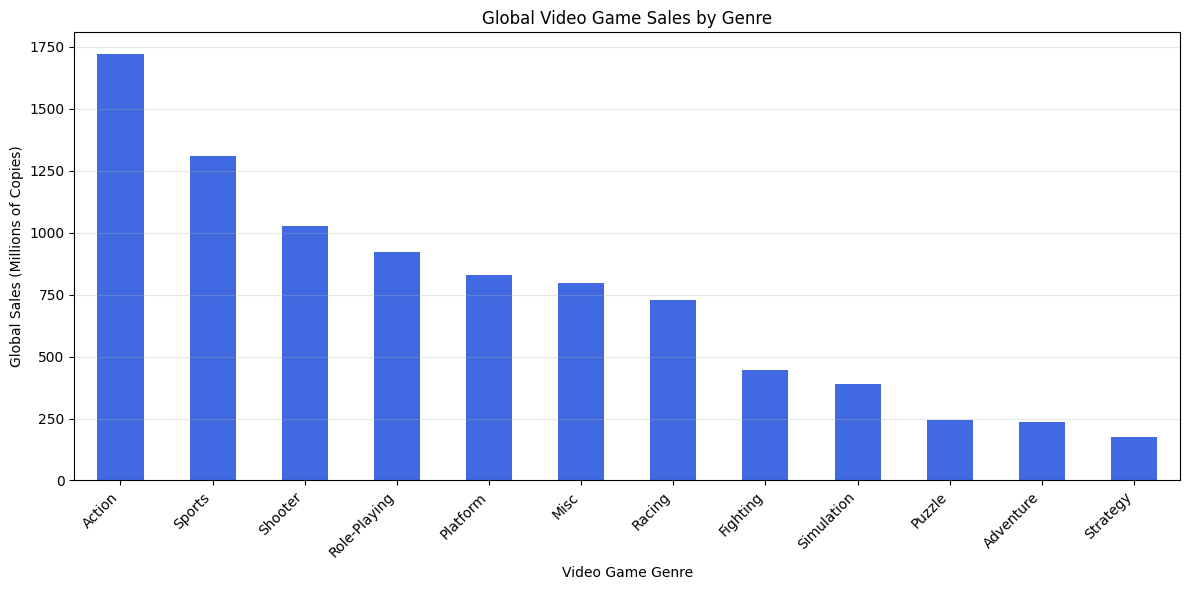

In [31]:
# Chart 1: Global sales by genre
plt.figure(figsize=(12, 6))

genre_sales.plot(kind="bar", color="royalblue")

plt.title("Global Video Game Sales by Genre")
plt.xlabel("Video Game Genre")
plt.ylabel("Global Sales (Millions of Copies)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

In [32]:
# Save the chart
plt.savefig("genre_sales.png", dpi=300, bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

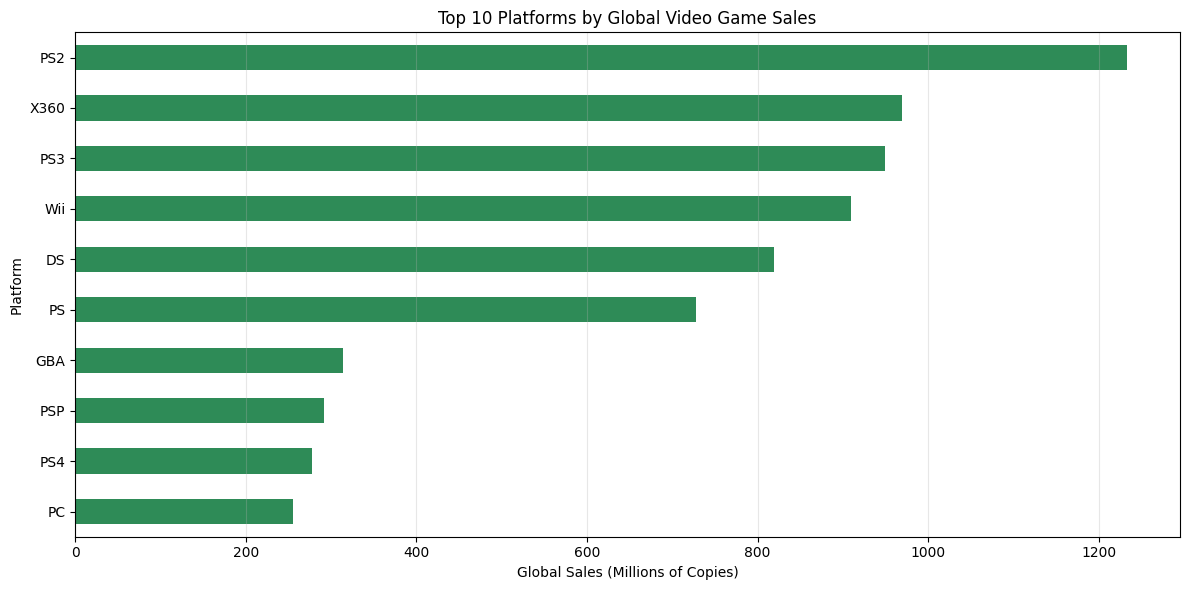

In [33]:
# Chart 2: Top 10 platforms by global sales
plt.figure(figsize=(12, 6))

top_platforms.sort_values().plot(
    kind="barh",
    color="seagreen"
)

plt.title("Top 10 Platforms by Global Video Game Sales")
plt.xlabel("Global Sales (Millions of Copies)")
plt.ylabel("Platform")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

In [35]:
# Save the chart
plt.savefig("platform_sales.png", dpi=300, bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

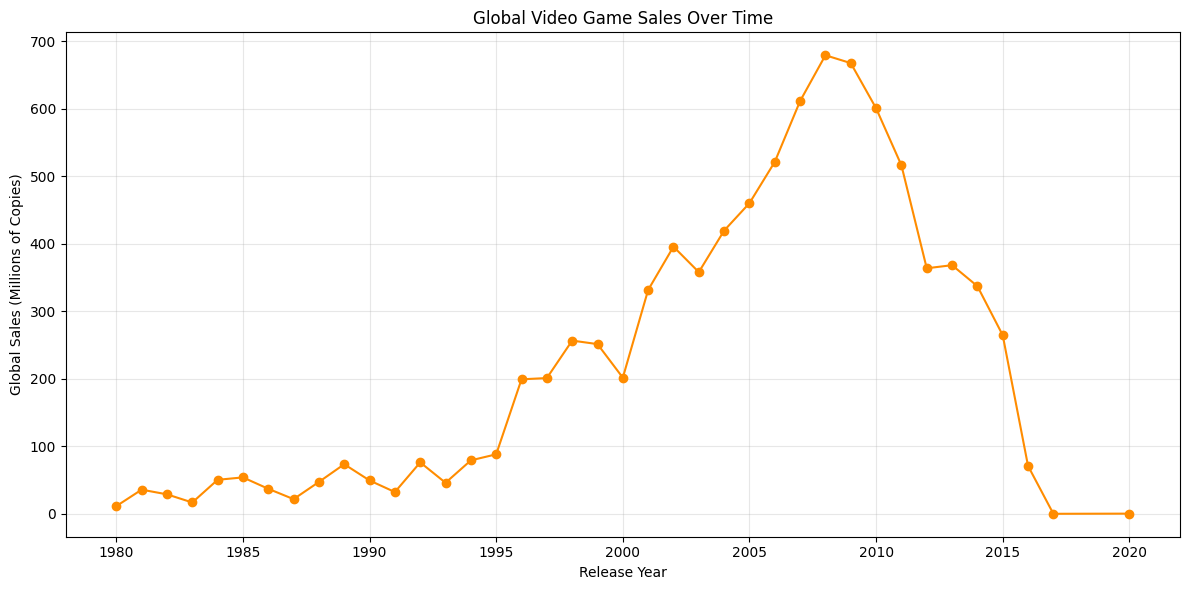

In [36]:
# Chart 3: Global sales trends over time
# Group sales by release year
yearly_sales = df_clean.groupby("Year")["Global_Sales"].sum()

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker="o",
    color="darkorange"
)

plt.title("Global Video Game Sales Over Time")
plt.xlabel("Release Year")
plt.ylabel("Global Sales (Millions of Copies)")
plt.grid(alpha=0.3)
plt.tight_layout()

In [37]:
# Save the chart
plt.savefig("yearly_sales.png", dpi=300, bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

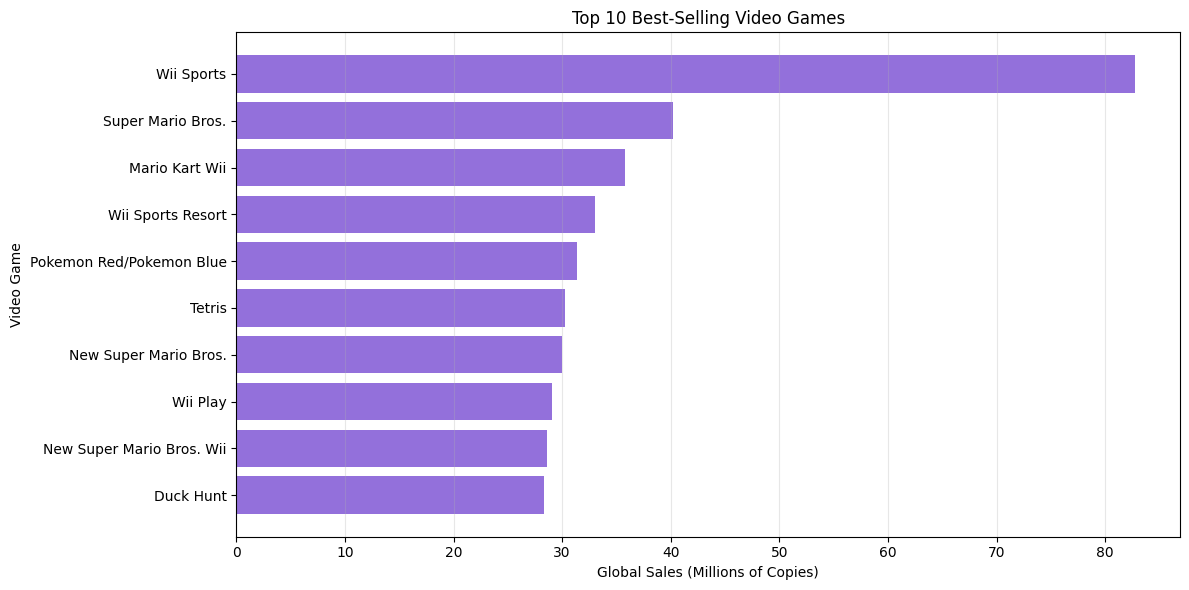

In [38]:
# Chart 4: Top 10 best-selling video games
plt.figure(figsize=(12, 6))

top_games_chart = top_10_games.sort_values("Global_Sales")

plt.barh(
    top_games_chart["Name"],
    top_games_chart["Global_Sales"],
    color="mediumpurple"
)

plt.title("Top 10 Best-Selling Video Games")
plt.xlabel("Global Sales (Millions of Copies)")
plt.ylabel("Video Game")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()


In [39]:
# Save the chart
plt.savefig("top_10_games.png", dpi=300, bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

In [40]:
# Verify that all chart files were saved
import os

charts = [
    "genre_sales.png",
    "platform_sales.png",
    "yearly_sales.png",
    "top_10_games.png"
]

for chart in charts:
    if os.path.exists(chart):
        print(chart, "- Saved successfully!")
    else:
        print(chart, "- File not found")

genre_sales.png - Saved successfully!
platform_sales.png - Saved successfully!
yearly_sales.png - Saved successfully!
top_10_games.png - Saved successfully!


## Statistical Analysis

In this section, I calculate descriptive statistics and analyze the distribution of global video game sales.

In [41]:
# Calculate descriptive statistics for global sales
sales_stats = df_clean["Global_Sales"].describe()

print("Global Sales Statistics:")
print(sales_stats)

Global Sales Statistics:
count    16327.000000
mean         0.540232
std          1.565732
min          0.010000
25%          0.060000
50%          0.170000
75%          0.480000
max         82.740000
Name: Global_Sales, dtype: float64


In [42]:
# Calculate mean and median global sales
mean_sales = df_clean["Global_Sales"].mean()
median_sales = df_clean["Global_Sales"].median()

print(f"Average Global Sales: {mean_sales:.2f} million")
print(f"Median Global Sales: {median_sales:.2f} million")

Average Global Sales: 0.54 million
Median Global Sales: 0.17 million


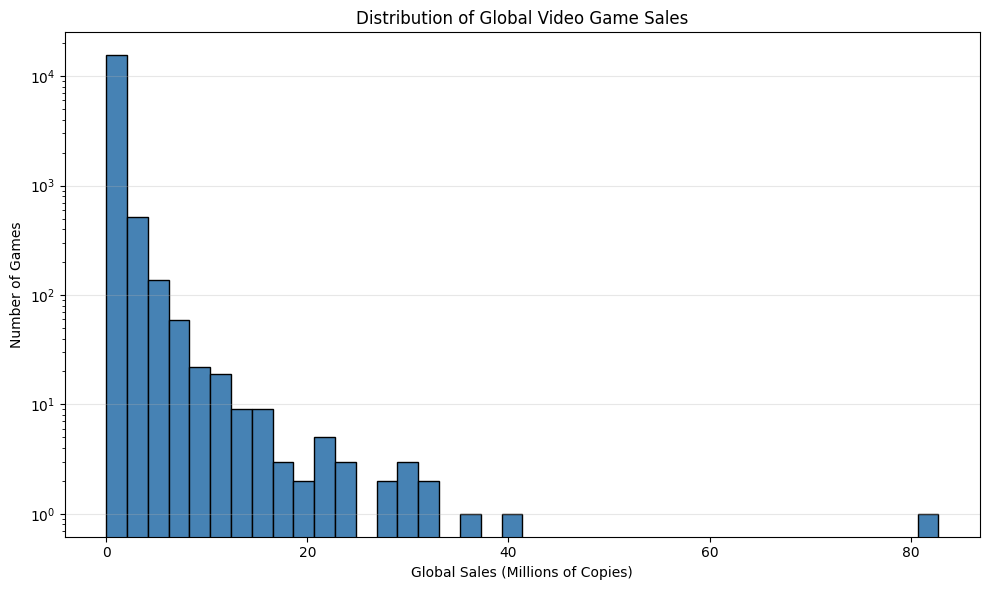

In [46]:

# Create and save the sales distribution histogram
plt.figure(figsize=(10, 6))

plt.hist(
    df_clean["Global_Sales"],
    bins=40,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Global Video Game Sales")
plt.xlabel("Global Sales (Millions of Copies)")
plt.ylabel("Number of Games")
plt.yscale("log")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("sales_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [44]:
# Save before displaying the chart
plt.savefig("sales_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [45]:
# Calculate average sales by platform
average_platform_sales = (
    df_clean.groupby("Platform")["Global_Sales"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Global Sales by Platform:")
print(average_platform_sales.head(10))

Average Global Sales by Platform:
Platform
GB      2.622887
NES     2.561939
GEN     1.050370
SNES    0.837029
PS4     0.827679
X360    0.785109
2600    0.746293
PS3     0.728029
Wii     0.705279
N64     0.690538
Name: Global_Sales, dtype: float64


### Statistical Analysis Summary

I calculated descriptive statistics to understand global video game sales, including the mean, median, minimum, maximum, and standard deviation.

I also created a histogram to examine the distribution of sales and compared average sales across platforms.

These statistics help explain differences between typical game sales and unusually successful titles.

In [47]:
# Final statistical summary
print("STATISTICAL SUMMARY")
print("---------------------------")

print("Total games:", len(df_clean))
print("Mean sales:", round(df_clean["Global_Sales"].mean(), 2))
print("Median sales:", round(df_clean["Global_Sales"].median(), 2))
print("Standard deviation:", round(df_clean["Global_Sales"].std(), 2))
print("Maximum sales:", df_clean["Global_Sales"].max())
print("Minimum sales:", df_clean["Global_Sales"].min())

STATISTICAL SUMMARY
---------------------------
Total games: 16327
Mean sales: 0.54
Median sales: 0.17
Standard deviation: 1.57
Maximum sales: 82.74
Minimum sales: 0.01


### Statistical Findings

The cleaned dataset contains 16,327 video game records. The average global sales per record is 0.54 million copies, while the median is only 0.17 million copies.

The mean is considerably higher than the median, suggesting a right-skewed sales distribution in which a small number of highly successful games increase the average.

The standard deviation is 1.57 million copies, indicating substantial variation in sales. The highest recorded sales are 82.74 million copies for Wii Sports.

These findings suggest that video game sales are unevenly distributed, with a relatively small number of best-selling titles achieving much higher sales than a typical game.